In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')


In [2]:
data = pd.read_csv(r'DataCoSupplyChainDataset.csv', encoding='latin1')
data

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class


In [3]:
describe = data.describe()
describe

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


In [4]:
# Modify column header format
data.columns = data.columns.str.lower().str.strip().str.replace(' ', '_').str.replace(r'[()]', '', regex=True)
data

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,...,order_zipcode,product_card_id,product_category_id,product_description,product_image,product_name,product_price,product_status,shipping_date_dateorders,shipping_mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class


In [5]:
# Change the date to datetime type
data['order_date_dateorders'] = pd.to_datetime(data['order_date_dateorders'])
data['shipping_date_dateorders'] = pd.to_datetime(data['shipping_date_dateorders'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   type                         180519 non-null  object        
 1   days_for_shipping_real       180519 non-null  int64         
 2   days_for_shipment_scheduled  180519 non-null  int64         
 3   benefit_per_order            180519 non-null  float64       
 4   sales_per_customer           180519 non-null  float64       
 5   delivery_status              180519 non-null  object        
 6   late_delivery_risk           180519 non-null  int64         
 7   category_id                  180519 non-null  int64         
 8   category_name                180519 non-null  object        
 9   customer_city                180519 non-null  object        
 10  customer_country             180519 non-null  object        
 11  customer_email            

In [6]:
cutoff_date = pd.Timestamp('2017-10-01')
data = data[data['order_date_dateorders'] < cutoff_date].copy()

In [7]:
data.isnull().sum()

type                                0
days_for_shipping_real              0
days_for_shipment_scheduled         0
benefit_per_order                   0
sales_per_customer                  0
delivery_status                     0
late_delivery_risk                  0
category_id                         0
category_name                       0
customer_city                       0
customer_country                    0
customer_email                      0
customer_fname                      0
customer_id                         0
customer_lname                      0
customer_password                   0
customer_segment                    0
customer_state                      0
customer_street                     0
customer_zipcode                    0
department_id                       0
department_name                     0
latitude                            0
longitude                           0
market                              0
order_city                          0
order_countr

In [8]:
data = data.drop(columns = ['product_description', 'order_zipcode', 'customer_zipcode', 
                            'customer_email', 'customer_password'])

In [9]:
data.isnull().sum()

type                           0
days_for_shipping_real         0
days_for_shipment_scheduled    0
benefit_per_order              0
sales_per_customer             0
delivery_status                0
late_delivery_risk             0
category_id                    0
category_name                  0
customer_city                  0
customer_country               0
customer_fname                 0
customer_id                    0
customer_lname                 0
customer_segment               0
customer_state                 0
customer_street                0
department_id                  0
department_name                0
latitude                       0
longitude                      0
market                         0
order_city                     0
order_country                  0
order_customer_id              0
order_date_dateorders          0
order_id                       0
order_item_cardprod_id         0
order_item_discount            0
order_item_discount_rate       0
order_item

In [10]:
data['ORDER_YEAR'] = data['order_date_dateorders'].dt.year
data['ORDER_MONTH'] = data['order_date_dateorders'].dt.month
data['ORDER_DAY'] = data['order_date_dateorders'].dt.day
data['ORDER_WEEKDAY'] = data['order_date_dateorders'].dt.weekday
data['ORDER_DATE'] = data['order_date_dateorders'].dt.date
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 171962 entries, 48 to 180518
Data columns (total 53 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   type                         171962 non-null  object        
 1   days_for_shipping_real       171962 non-null  int64         
 2   days_for_shipment_scheduled  171962 non-null  int64         
 3   benefit_per_order            171962 non-null  float64       
 4   sales_per_customer           171962 non-null  float64       
 5   delivery_status              171962 non-null  object        
 6   late_delivery_risk           171962 non-null  int64         
 7   category_id                  171962 non-null  int64         
 8   category_name                171962 non-null  object        
 9   customer_city                171962 non-null  object        
 10  customer_country             171962 non-null  object        
 11  customer_fname               1

# M4 Exploratory Data Analytics Report Notebook

This notebook keeps the original data preprocessing workflow, preserves the existing EDA visualisations, and reorganizes the full analysis into the required M4 structure: univariate, bivariate, and multivariate analysis. Every chart is followed by a written interpretation, and the notebook ends with revised hypotheses and a clear modelling question.


In [11]:
# EDA display settings
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11
pd.set_option('display.max_columns', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

def format_percent_axis(ax, axis='y'):
    formatter = plt.FuncFormatter(lambda value, _: f'{value:.0%}')
    if axis == 'x':
        ax.xaxis.set_major_formatter(formatter)
    else:
        ax.yaxis.set_major_formatter(formatter)
    return ax


## Dataset Scope After Preprocessing

The following summary documents the dataset after the original preprocessing cells above. It helps the report reader understand the sample size and date range used by all EDA visualisations.


In [12]:
print(f"Rows after preprocessing: {data.shape[0]:,}")
print(f"Columns after preprocessing: {data.shape[1]:,}")
print(f"Date range: {data['order_date_dateorders'].min().date()} to {data['order_date_dateorders'].max().date()}")
print(f"Unique customers: {data['customer_id'].nunique():,}")
print(f"Unique products: {data['product_name'].nunique():,}")
print(f"Markets: {data['market'].nunique():,}")

data[['sales', 'sales_per_customer', 'benefit_per_order', 'order_item_quantity',
      'days_for_shipping_real', 'days_for_shipment_scheduled', 'late_delivery_risk']].describe().T


Rows after preprocessing: 171,962
Columns after preprocessing: 53
Date range: 2015-01-01 to 2017-09-30
Unique customers: 12,330
Unique products: 100
Markets: 5


,count,mean,std,min,25%,50%,75%,max
sales,"171,962.00",199.16,111.83,9.99,119.98,199.92,299.95,"1,999.99"
sales_per_customer,"171,962.00",178.96,101.68,7.49,105.58,163.93,245.00,"1,699.99"
benefit_per_order,"171,962.00",21.43,97.48,"-1,844.98",7.41,31.67,63.86,721.60
order_item_quantity,"171,962.00",2.18,1.47,1.00,1.00,1.00,3.00,5.00
days_for_shipping_real,"171,962.00",3.50,1.62,0.00,2.00,3.00,5.00,6.00
days_for_shipment_scheduled,"171,962.00",2.93,1.37,0.00,2.00,4.00,4.00,4.00
late_delivery_risk,"171,962.00",0.55,0.50,0.00,0.00,1.00,1.00,1.00


**Interpretation:** The filtered dataset remains large enough for exploratory comparisons across markets, product categories, delivery outcomes, and customer segments. Because each row represents an order item, interpretations are made at the order-item level unless the chart explicitly groups by customer or region.


## Original Team Hypotheses

The team's original hypotheses were:

1. Product-driven businesses show significant variation across product categories, so product features should have a strong impact on sales.
2. Sales may exhibit seasonal distribution over time.
3. Transfer-payment security is relatively weak, and fraud may be related to payment methods.
4. Western Europe and Central America may be high-fraud areas.
5. Fraud rate may be related to the economic level of geographic regions and payment methods.

The team expected to verify or falsify these conjectures through random forest feature importance analysis, regional comparison of fraud rates, and RFM stratification. The original EDA below is preserved first, then supplemental charts are added to cover the full M4 requirements.


# 1. Univariate Analysis

Univariate analysis examines one variable at a time. In this section, the charts describe the distributions, rankings, and composition of sales, profit, products, markets, regions, fraud-related categories, and customer segments.


## 1.1 Sales Distribution and Outliers


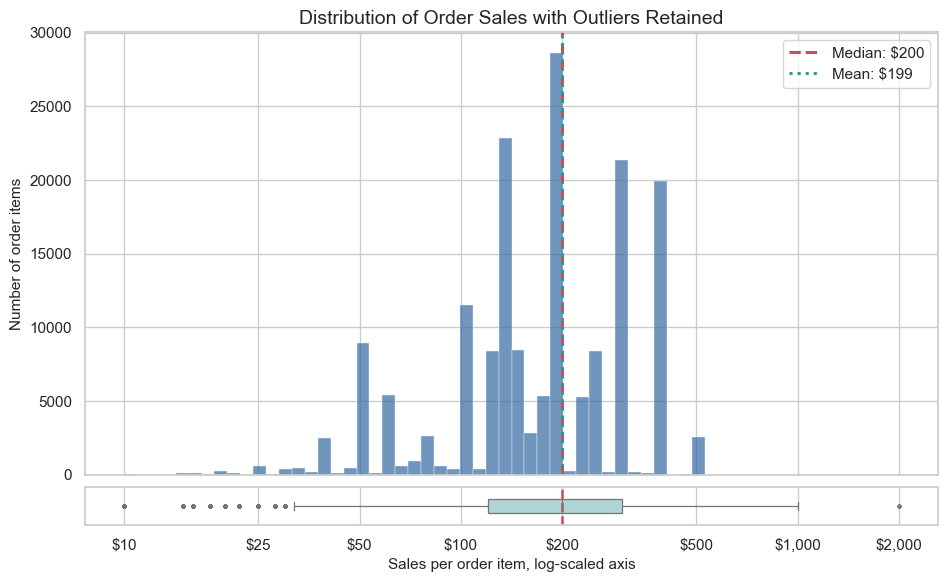

Mean sales: $199.16
Median sales: $199.92
Upper outlier threshold using 1.5*IQR rule: $569.91
Share above this threshold: 0.01%


In [13]:
plot_sales = data[['sales']].copy()
plot_sales['log_sales'] = np.log10(plot_sales['sales'])
median_sales = data['sales'].median()
mean_sales = data['sales'].mean()
median_log = np.log10(median_sales)
mean_log = np.log10(mean_sales)

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 6.4),
    gridspec_kw={'height_ratios': [5.2, 0.45], 'hspace': 0.05},
    sharex=True
)

sns.histplot(
    data=plot_sales,
    x='log_sales',
    bins=60,
    color='#3A6EA5',
    alpha=0.72,
    edgecolor='white',
    linewidth=0.25,
    ax=axes[0]
)
axes[0].axvline(median_log, color='#D1495B', linestyle='--', linewidth=2.2, label=f"Median: ${median_sales:,.0f}")
axes[0].axvline(mean_log, color='#2A9D8F', linestyle=':', linewidth=2.2, label=f"Mean: ${mean_sales:,.0f}")
axes[0].set_title('Distribution of Order Sales with Outliers Retained')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of order items')
axes[0].legend(loc='upper right')

sns.boxplot(
    data=plot_sales,
    x='log_sales',
    ax=axes[1],
    color='#A8DADC',
    fliersize=1.8,
    linewidth=0.9,
    width=0.38
)
axes[1].axvline(median_log, color='#D1495B', linestyle='--', linewidth=1.8)
axes[1].set_yticks([])
axes[1].set_ylabel('')
axes[1].set_xlabel('Sales per order item, log-scaled axis')

sales_ticks = np.array([10, 25, 50, 100, 200, 500, 1000, 2000])
axes[1].set_xticks(np.log10(sales_ticks))
axes[1].set_xticklabels([f'${value:,.0f}' for value in sales_ticks])

plt.tight_layout()
plt.show()

q1 = data['sales'].quantile(0.25)
q3 = data['sales'].quantile(0.75)
iqr = q3 - q1
outlier_threshold = q3 + 1.5 * iqr
outlier_share = (data['sales'] > outlier_threshold).mean()
print(f"Mean sales: ${mean_sales:,.2f}")
print(f"Median sales: ${median_sales:,.2f}")
print(f"Upper outlier threshold using 1.5*IQR rule: ${outlier_threshold:,.2f}")
print(f"Share above this threshold: {outlier_share:.2%}")


**Interpretation:** The full sales range is retained and shown on a log-scaled x-axis so the concentration of typical orders and the high-value tail can be seen together. The median is marked with a dashed red line, and the histogram shows that most orders cluster in the lower-to-middle sales range while fewer high-value orders extend the right tail. These outliers are not removed because they represent real high-value business orders; keeping them preserves the authenticity of the dataset and avoids hiding important sales behavior.


## 1.2 Benefit Per Order Distribution with Focused X-Axis


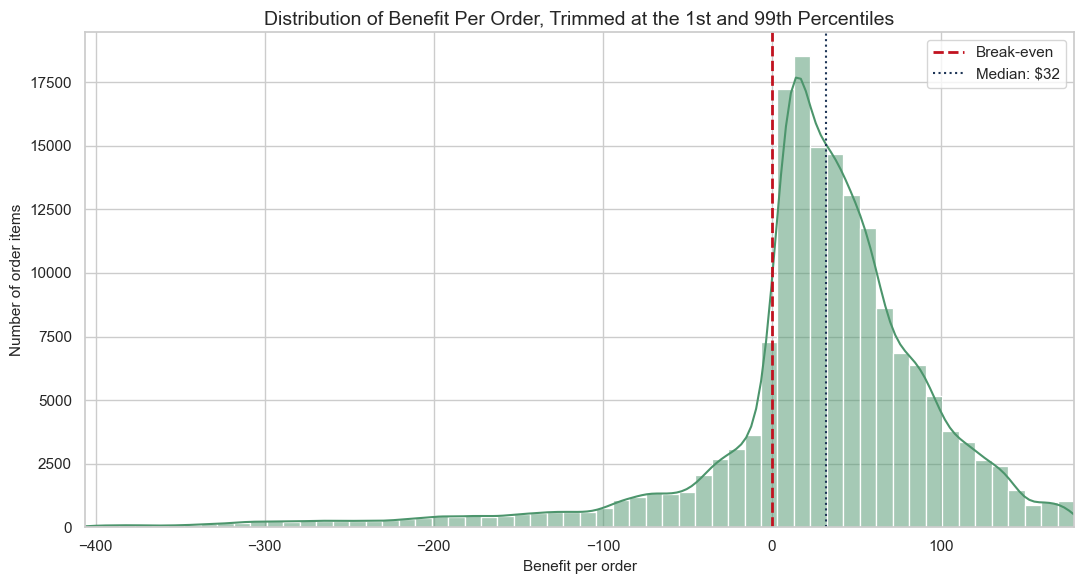

Share of order items with negative benefit: 18.71%


In [14]:
benefit_lower = data['benefit_per_order'].quantile(0.01)
benefit_upper = data['benefit_per_order'].quantile(0.99)
plot_benefit = data[data['benefit_per_order'].between(benefit_lower, benefit_upper)]

fig, ax = plt.subplots(figsize=(11, 6))
sns.histplot(data=plot_benefit, x='benefit_per_order', bins=60, kde=True, ax=ax, color='#4C956C')
ax.axvline(0, color='#C1121F', linestyle='--', linewidth=2, label='Break-even')
ax.axvline(data['benefit_per_order'].median(), color='#1D3557', linestyle=':', label=f"Median: ${data['benefit_per_order'].median():,.0f}")
ax.set_xlim(benefit_lower, benefit_upper)
ax.set_title('Distribution of Benefit Per Order, Trimmed at the 1st and 99th Percentiles')
ax.set_xlabel('Benefit per order')
ax.set_ylabel('Number of order items')
ax.legend()
plt.tight_layout()
plt.show()

loss_rate = (data['benefit_per_order'] < 0).mean()
print(f"Share of order items with negative benefit: {loss_rate:.2%}")


**Interpretation:** The focused x-axis makes the negative-profit region easier to see. A meaningful share of order items falls below zero benefit, so product, region, shipping, and discount variables should be evaluated not only for sales but also for profitability risk.


## 1.3 Top Ten Products by Quantity Sold


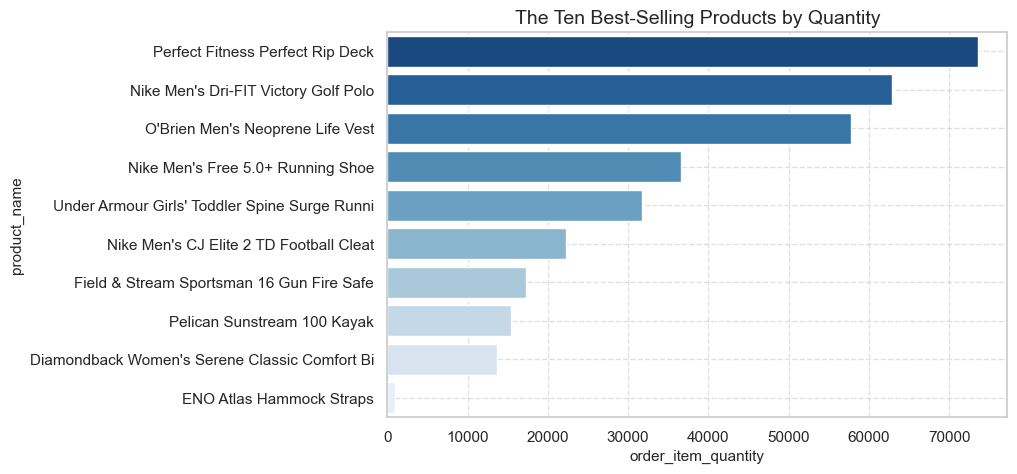

In [15]:
# Find the top ten best-selling products by order quantity
top_products = data.groupby('product_name')['order_item_quantity'].sum().reset_index()
top_products = top_products.sort_values(by='order_item_quantity', ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x='order_item_quantity', y='product_name', data=top_products, 
            hue='product_name', dodge=False, palette='Blues_r', legend=False)
plt.title("The Ten Best-Selling Products by Quantity")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Interpretation:** A small number of products account for the highest quantities sold. This supports the original product-driven hypothesis: product identity and category are likely important for understanding sales performance.


## 1.4 Total Sales by Market


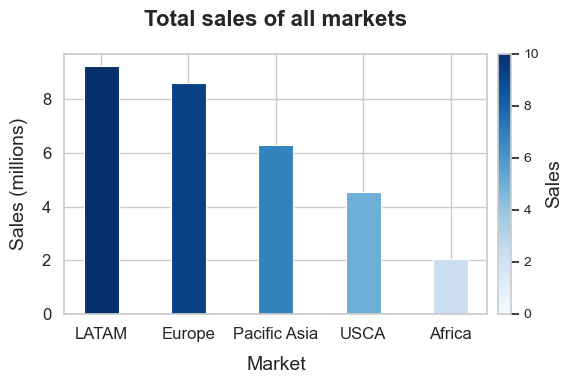

In [16]:
market = data.groupby('market')  

# Create a blue gradient color mapping
cmap = plt.cm.Blues
norm = Normalize(vmin=0, vmax=10)  


fig, ax = plt.subplots(figsize=(6, 4), dpi=100)  
market_sum = market['sales_per_customer'].sum().sort_values(ascending=False)
x = market_sum.index
y = market_sum.values / 1e6  

# Map y data to the range of 0 to 10
y_normalized = y / (y.max() / 10)  


colors = cmap(norm(y_normalized))  
bars = ax.bar(x, y, color=colors, edgecolor='white', linewidth=0.8, width=0.4)  

# Add title and label
ax.set_title("Total sales of all markets", fontsize=16, pad=20, fontweight='bold') 
ax.set_xlabel("Market", fontsize=14, labelpad=10)
ax.set_ylabel("Sales (millions)", fontsize=14, labelpad=10)  

# Set scale font and rotation angle
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)

# Add color bar
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  
cbar = fig.colorbar(sm, orientation='vertical', pad=0.02, aspect=20, ax=ax)  
cbar.set_label('Sales', fontsize=14) 
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

**Interpretation:** Total sales per customer are concentrated in certain markets. Market should therefore be included in later analysis because overall sales patterns may be shaped by geography.


## 1.5 Total Sales by Region


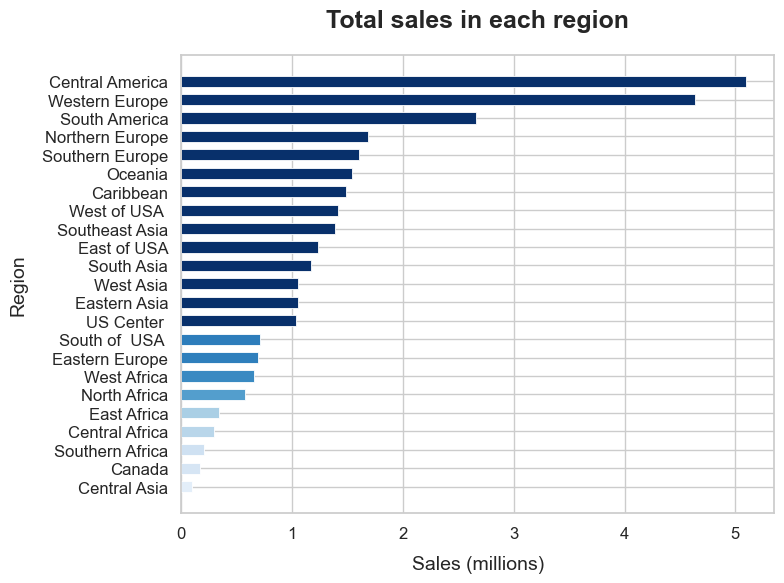

In [17]:
region = data.groupby('order_region')

cmap = plt.cm.Blues
norm = Normalize(vmin=0, vmax=1)

plt.figure(figsize=(8, 6), dpi=100) 
region_sum = region['sales_per_customer'].sum().sort_values(ascending=True) 
x = region_sum.values / 1e6
y = region_sum.index

colors = cmap(norm(x))
plt.barh(y, x, color=colors, edgecolor='white', linewidth=0.6, height=0.6)

plt.title("Total sales in each region", fontsize=18, pad=20, fontweight='bold')
plt.xlabel("Sales (millions)", fontsize=14, labelpad=10) 
plt.ylabel("Region", fontsize=14, labelpad=10)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

**Interpretation:** Sales also vary substantially by order region. This suggests that regional demand and market structure may influence sales outcomes, so regional comparisons should be rate-based rather than relying only on total counts.


## 1.6 Loss-Making Product Categories


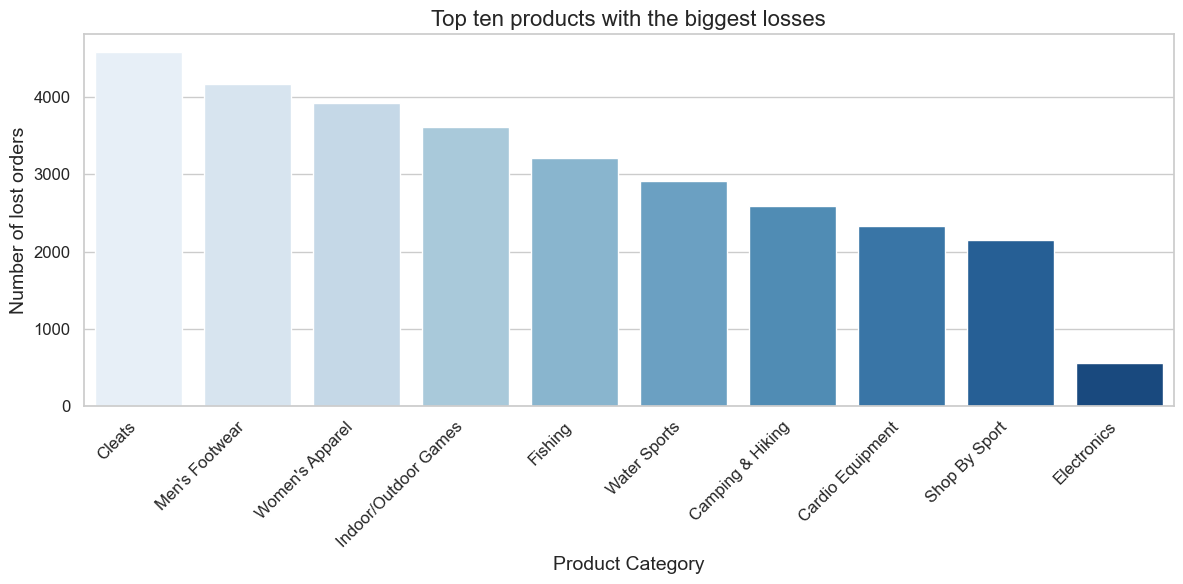

In [18]:
loss = data[data['benefit_per_order'] < 0]

plt.figure(figsize=(12, 6))
loss_products = loss['category_name'].value_counts().nlargest(10)
sns.barplot(x=loss_products.index, y=loss_products.values, hue=loss_products.index, palette='Blues')
plt.title('Top ten products with the biggest losses', fontsize=16)
plt.xlabel('Product Category', fontsize=14)
plt.ylabel('Number of lost orders', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12) 
plt.yticks(fontsize=12) 
plt.tight_layout()
plt.show()


**Interpretation:** Loss-making orders are concentrated in particular product categories. This means product features do not only affect sales volume; they may also affect profitability risk.


## 1.7 Suspected Fraud Distribution by Region


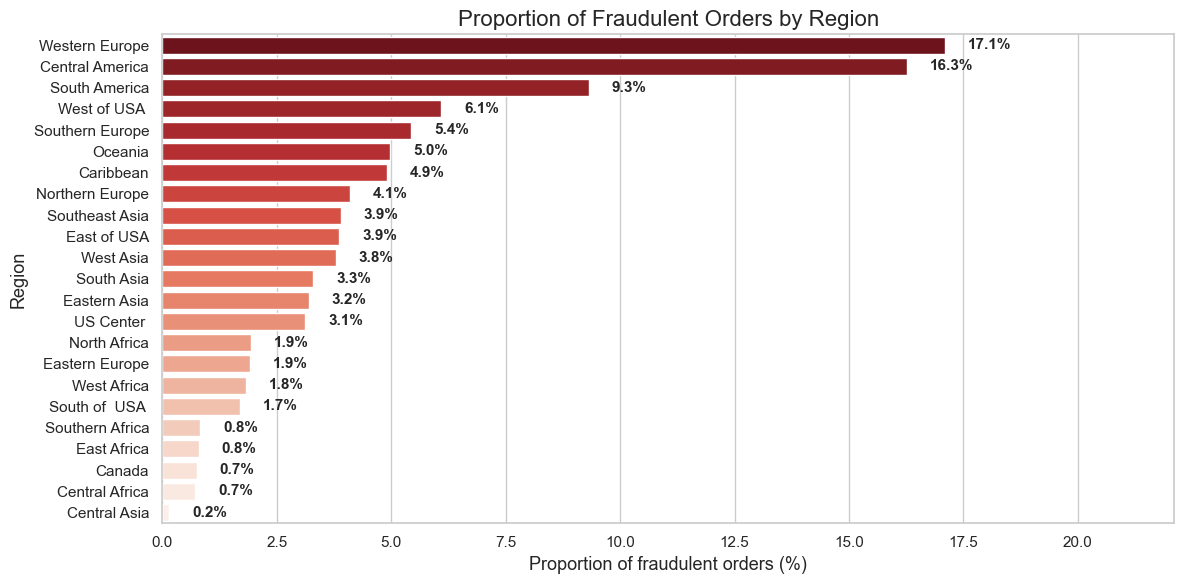

In [19]:
fraud_orders = data[data['order_status'] == 'SUSPECTED_FRAUD']
# Statistics on the number and proportion of fraudulent orders by region
fraud_region_count = fraud_orders['order_region'].value_counts()
fraud_region_pct = fraud_region_count / fraud_region_count.sum() * 100
fraud_region_df = fraud_region_pct.reset_index()
fraud_region_df.columns = ['order_region', 'fraud_pct']

# Draw a horizontal bar chart
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    y='order_region',
    x='fraud_pct',
    data=fraud_region_df,
    hue='order_region',
    palette='Reds_r'
)


for i, v in enumerate(fraud_region_df['fraud_pct']):
    ax.text(v + 0.5, i, f"{v:.1f}%", va='center', fontsize=11, fontweight='bold')

plt.title("Proportion of Fraudulent Orders by Region", fontsize=16)
plt.xlabel("Proportion of fraudulent orders (%)", fontsize=13)
plt.ylabel("Region", fontsize=13)
plt.xlim(0, fraud_region_df['fraud_pct'].max() + 5)
plt.tight_layout()
plt.show()


**Interpretation:** Suspected fraud orders are not evenly distributed across regions. However, this chart shows the distribution among fraud cases, so the report should also compare fraud rates by region before concluding that a region is truly high-risk.


## 1.8 Suspected Fraud by Payment Method


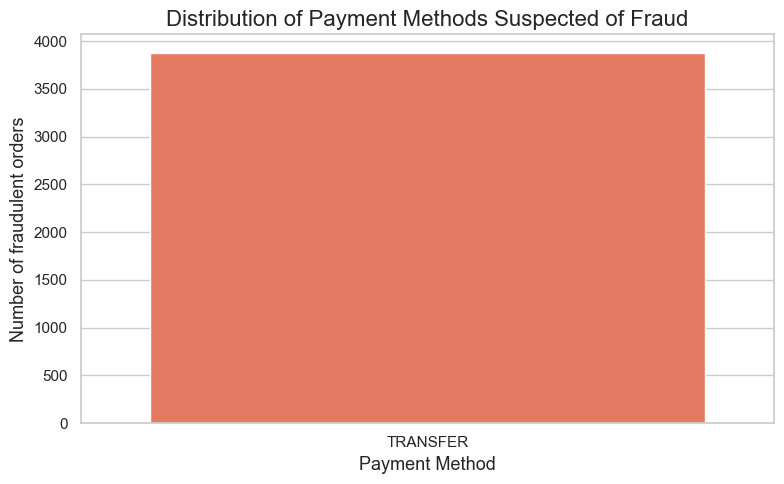

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

data['customer_full_name'] = data['customer_fname'].astype(str) + ' ' + data['customer_lname'].astype(str)
fraud_orders = data[data['order_status'] == 'SUSPECTED_FRAUD']

fraud_payment = fraud_orders['type'].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(x=fraud_payment.index, y=fraud_payment.values, hue = fraud_payment.index, palette='Reds_r')
plt.title("Distribution of Payment Methods Suspected of Fraud", fontsize=16)
plt.xlabel("Payment Method", fontsize=13)
plt.ylabel("Number of fraudulent orders", fontsize=13)
plt.tight_layout()
plt.show()


**Interpretation:** Suspected fraud cases are concentrated among payment types. This partially supports the team's hypothesis that payment method may be related to fraud risk.


## 1.9 Suspected Fraud by Product Category


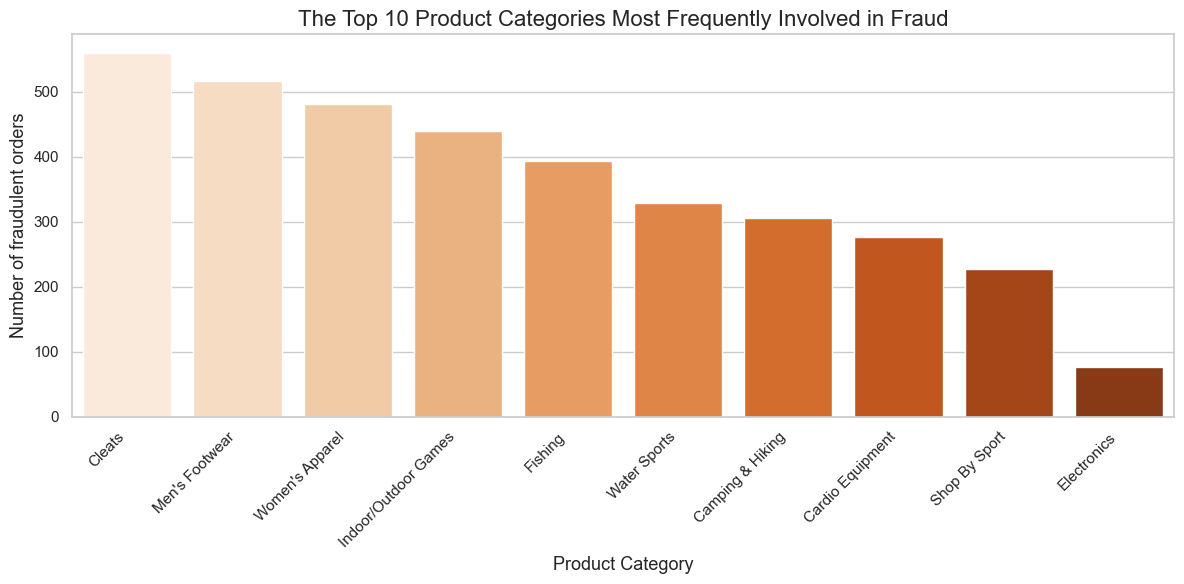

In [21]:
plt.figure(figsize=(12, 6))
fraud_cat = fraud_orders['category_name'].value_counts().nlargest(10)
sns.barplot(x=fraud_cat.index, y=fraud_cat.values, hue=fraud_cat.index, palette='Oranges', legend=False)
plt.title("The Top 10 Product Categories Most Frequently Involved in Fraud", fontsize=16)
plt.xlabel("Product Category", fontsize=13)
plt.ylabel("Number of fraudulent orders", fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Interpretation:** Some product categories appear more frequently in suspected fraud orders. This suggests that fraud risk may be associated with product type, although category-level fraud rates should also be checked because high-volume categories naturally produce more cases.


## 1.10 Customers with the Most Suspected Fraud Cases


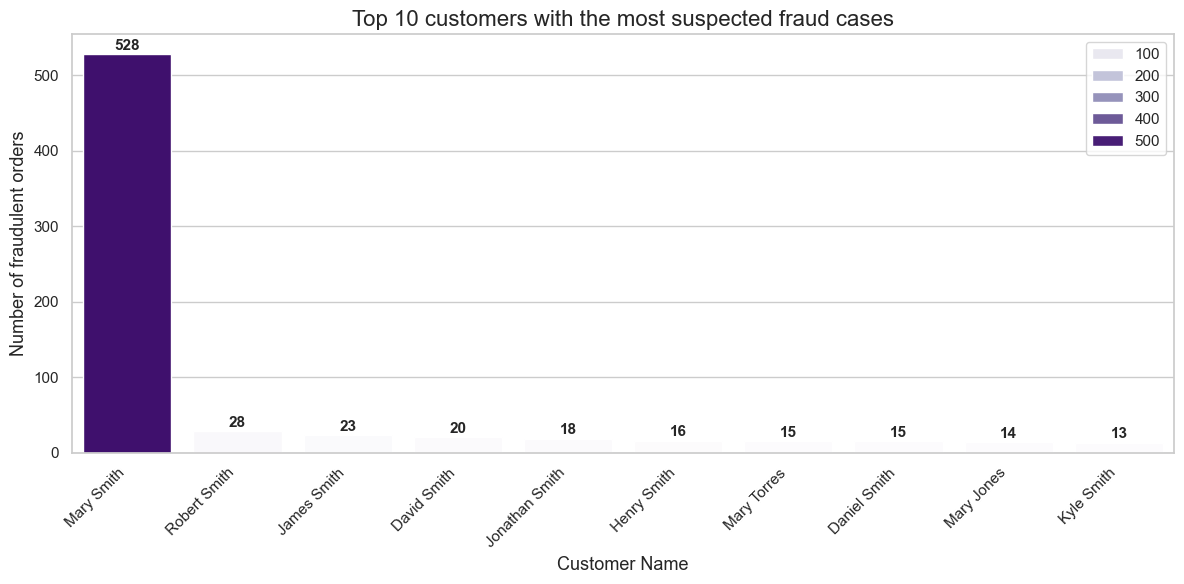

In [22]:
fraud_customers = fraud_orders['customer_full_name'].value_counts().nlargest(10)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=fraud_customers.index, y=fraud_customers.values, hue = fraud_customers.values, palette='Purples')
for i, v in enumerate(fraud_customers.values):
    ax.text(
        i, v + 2,                  
        f'{v}',                    
        ha='center', va='bottom',
        fontsize=11, fontweight='bold'
    )
plt.title("Top 10 customers with the most suspected fraud cases", fontsize=16)
plt.xlabel("Customer Name", fontsize=13)
plt.ylabel("Number of fraudulent orders", fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Interpretation:** A few customer names appear more often among suspected fraud cases. This may indicate repeated suspicious activity, but customer-level interpretation should be handled carefully because names may not uniquely identify individuals.


## 1.11 RFM Customer Segmentation Setup


In [23]:

data['order_date_dateorders'] = pd.to_datetime(data['order_date_dateorders'])

# Calculate the current date (assuming it is the maximum date in the data)
current_date = data['order_date_dateorders'].max()

# Filter key fields
rfm_data = data[['customer_id', 'order_date_dateorders', 'sales']]

# Rename the list for ease of handling
rfm_data.columns = ['customer_id', 'order_date', 'sales']

In [24]:
#Calculate R value (Recency)
#Time interval of last consumption (days):
recency_df = rfm_data.groupby('customer_id').order_date.max().reset_index()
recency_df['recency'] = (current_date - recency_df['order_date']).dt.days

#Calculate the F value (Frequency)
#Consumption frequency (number of orders):
frequency_df = rfm_data.groupby('customer_id').order_date.count().reset_index()
frequency_df.columns = ['customer_id', 'frequency']

#Calculate M value (Monetary)
#Consumption amount (total sales):
monetary_df = rfm_data.groupby('customer_id').sales.sum().reset_index()
monetary_df.columns = ['customer_id', 'monetary']

#Merge RFM values
#Merge the values of R, F, and M into one DataFrame:
rfm_df = recency_df.merge(frequency_df, on='customer_id').merge(monetary_df, on='customer_id')

In [25]:
#RFM scoring
#Divide the R, F, and M values into high and low intervals (which can be adjusted to more intervals according to business needs):

#R value
rfm_df['R_Score'] = pd.qcut(rfm_df['recency'], q=2, labels=[2, 1], duplicates='drop')

#F-value
rfm_df['F_Score'] = pd.qcut(rfm_df['frequency'], q=2, labels=[1, 2], duplicates='drop')

# M score
rfm_df['M_Score'] = pd.qcut(rfm_df['monetary'], q=2, labels=[1, 2], duplicates='drop')

#Customer segmentation
#According to the score combination of R, F, and M, customers are divided into the following 8 categories:

#Calculate RFM comprehensive score
rfm_df['RFM_Score'] = rfm_df['R_Score'].astype(str) + rfm_df['F_Score'].astype(str) + rfm_df['M_Score'].astype(str)

# # customer segmentation
customer_segments = {
    '222': 'Important Value Customer',
    '122': 'Important to retain customers',
    '212': 'Important development client',
    '112': 'Important to retain customers',
    '221': 'Regular Value Customer',
    '121': 'Regularly maintain customers',
    '211': 'General customer development',
    '111': 'Ordinary customer retention'
}

rfm_df['Customer_Segment'] = rfm_df['RFM_Score'].map(customer_segments)

## 1.12 RFM Customer Value Pyramid


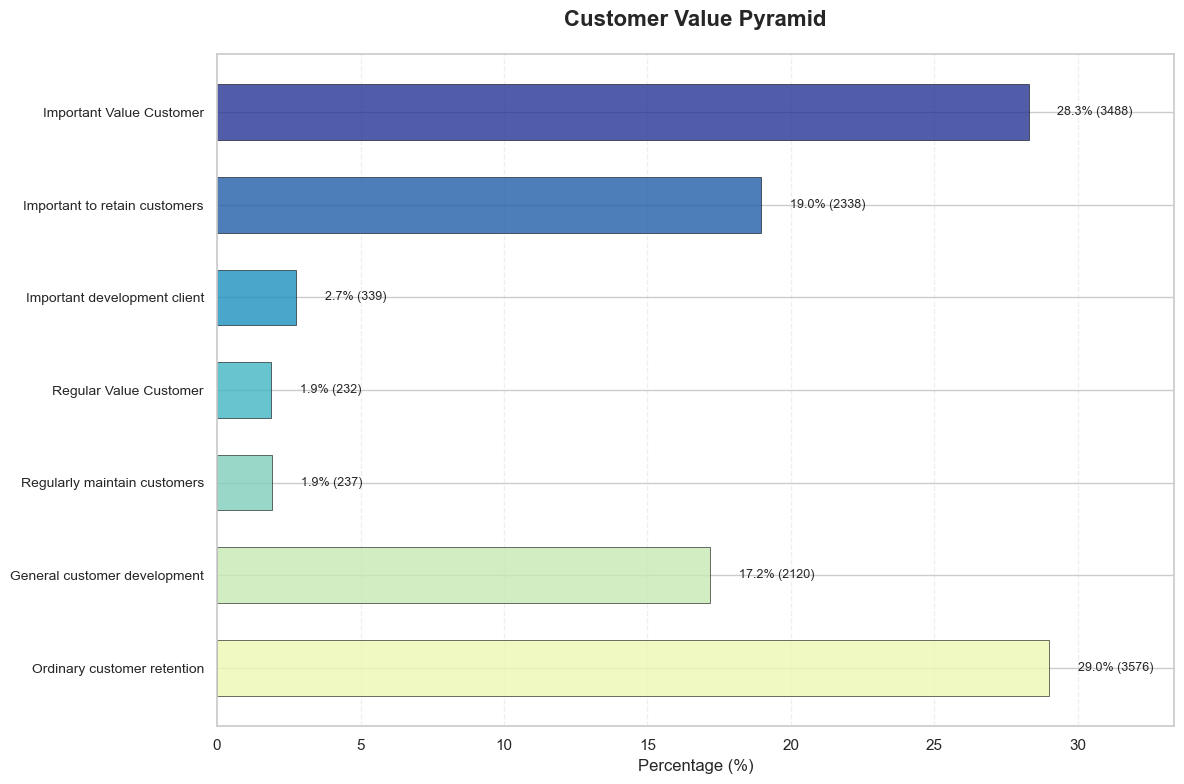

In [26]:

value_order = [
    'Important Value Customer',    
    'Important to retain customers', 
    'Important development client',  
    'Regular Value Customer',        
    'Regularly maintain customers',  
    'General customer development',  
    'Ordinary customer retention'   
]

# Obtain the number of customers in each tier
segment_counts = rfm_df['Customer_Segment'].value_counts()
ordered_counts = [segment_counts.get(segment, 0) for segment in value_order]


fig, ax = plt.subplots(figsize=(12, 8))


y_pos = np.arange(len(value_order))

# Draw a horizontal bar chart - display percentages on the left and actual quantities on the right
total_customers = sum(ordered_counts)
percentages = [count/total_customers*100 for count in ordered_counts]


bars_left = ax.barh(y_pos, percentages, height=0.6, color=sns.color_palette('YlGnBu_r', len(value_order)), 
                    alpha=0.8, edgecolor='black', linewidth=0.5)


ax.set_yticks(y_pos)
ax.set_yticklabels(value_order, fontsize=10)
ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_title('Customer Value Pyramid', fontsize=16, fontweight='bold', pad=20)


for i, (bar, percentage, count) in enumerate(zip(bars_left, percentages, ordered_counts)):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, 
            f'{percentage:.1f}% ({count})', 
            ha='left', va='center', fontsize=9)


ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)

# Reverse the Y-axis to place high-value customers at the top
ax.invert_yaxis()


ax.set_xlim(0, max(percentages) * 1.15)

plt.tight_layout()
plt.show()


**Interpretation:** The RFM value pyramid shows that customers are distributed unevenly across value groups. This supports using RFM stratification as a descriptive tool and potentially as a feature source in later modelling.


## 1.13 RFM Customer Segment Distribution


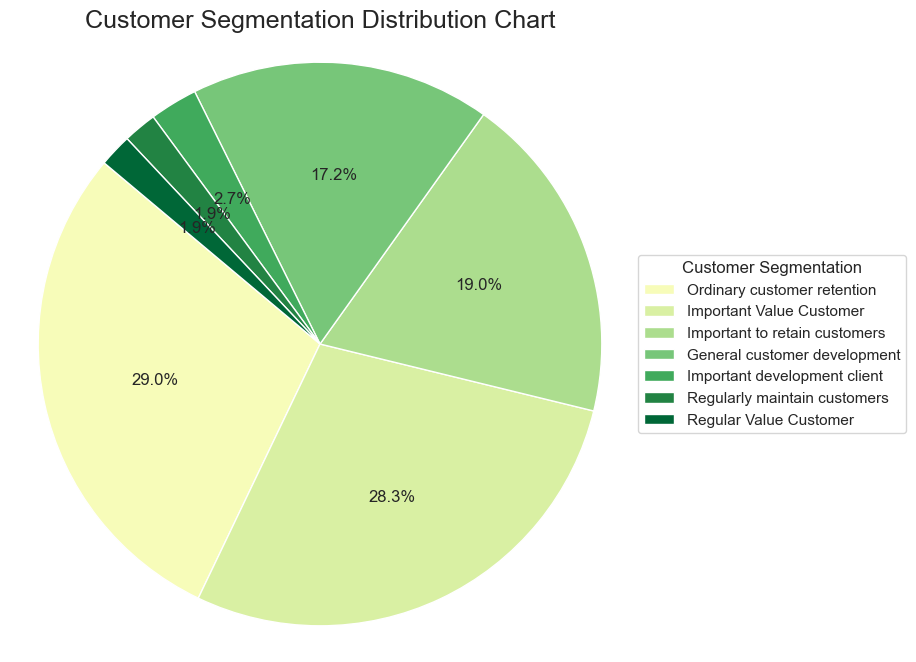

In [27]:
# Calculate the number of tiers for each customer
segment_counts = rfm_df['Customer_Segment'].value_counts()

# Pie chart
plt.figure(figsize=(8, 8))
plt.pie(segment_counts, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=sns.color_palette('YlGn', len(segment_counts)), 
        textprops={'fontsize': 12})


plt.legend(segment_counts.index, title="Customer Segmentation", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.title('Customer Segmentation Distribution Chart', fontsize=18)
plt.axis('equal')  
plt.show()

**Interpretation:** The pie chart gives a second view of the RFM segment distribution. It confirms that customer value groups are imbalanced, so recommendations should not assume that all customer segments contribute equally.


# 2. Bivariate Analysis

Bivariate analysis compares two variables at a time. These charts examine time and sales, hour and order volume, region and delay, shipping mode or market and delay risk, and sales versus benefit.


## 2.1 Monthly Sales by Year


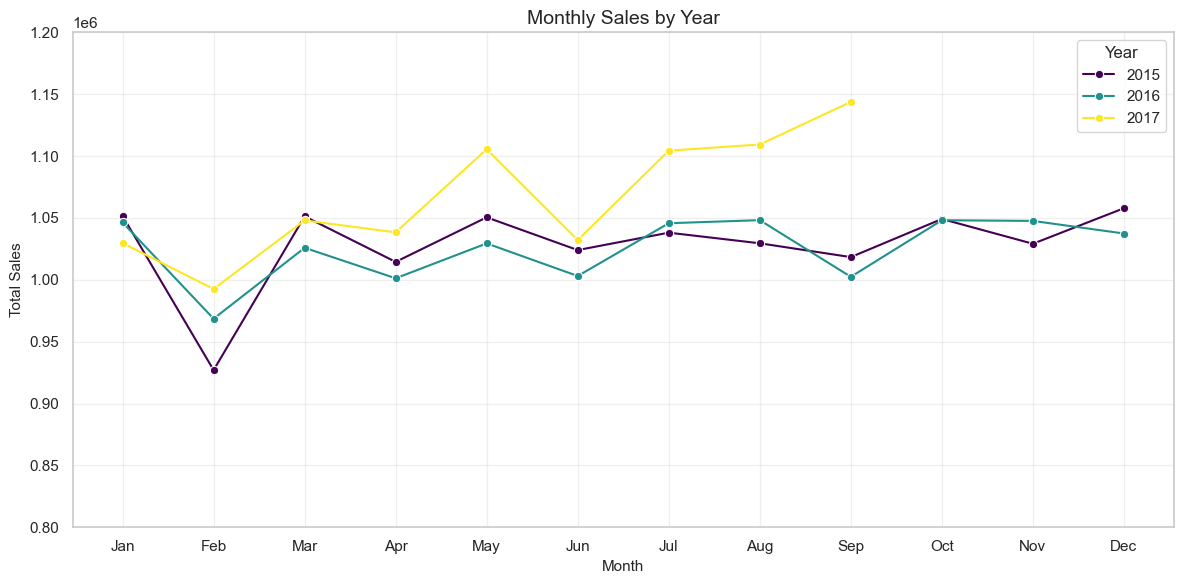

In [28]:
daily_orders = data.groupby(['order_date_dateorders'])['sales'].sum().reset_index()
daily_orders['year'] = daily_orders['order_date_dateorders'].dt.year
daily_orders['month'] = daily_orders['order_date_dateorders'].dt.month

monthly_orders_by_year = daily_orders.groupby(['year', 'month'])['sales'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_orders_by_year, x='month', y='sales', 
             hue='year', marker='o', palette='viridis')
plt.title('Monthly Sales by Year')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                         'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.legend(title='Year')
plt.grid(True, alpha=0.3)
plt.ylim(800000, 1200000)
plt.tight_layout()
plt.show()

**Interpretation:** Monthly sales vary across years and months rather than staying flat. This supports the team's expectation that sales may have a time pattern, although formal seasonality would need additional testing in the modelling stage.


## 2.2 Order Volume by Hour of Day


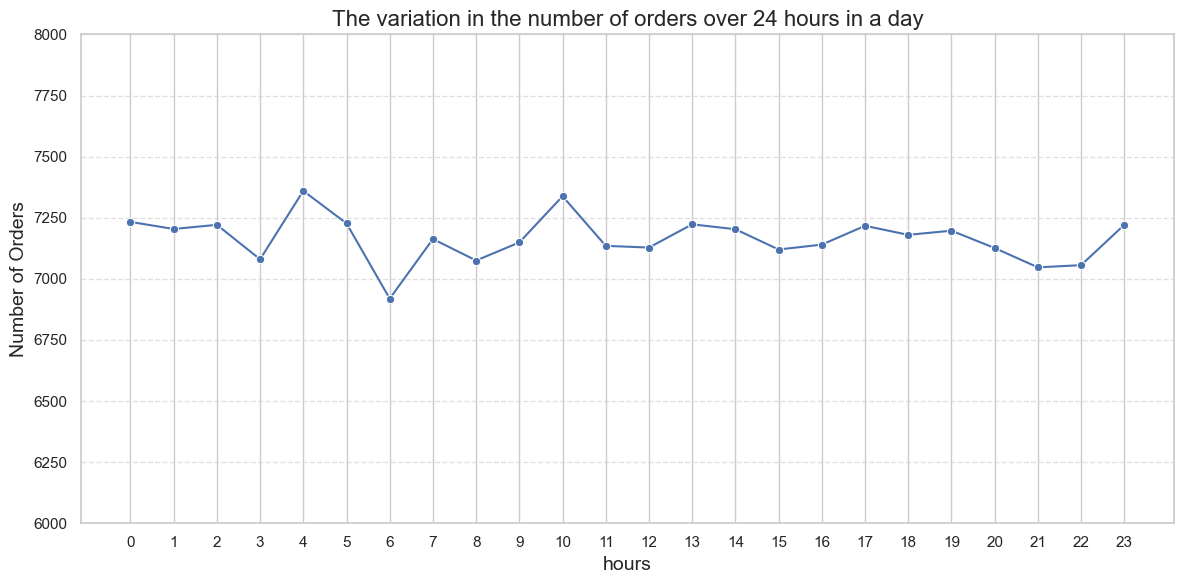

In [29]:
# Ensure that 'order_date_dateorders' is of type timestamp
data['order_date_dateorders'] = pd.to_datetime(data['order_date_dateorders'])

# Extract hourly information
data['hour'] = data['order_date_dateorders'].dt.hour

# Group by hour and calculate the number of orders placed
hourly_orders = data.groupby('hour').size().reset_index(name='order_count')

# Draw a bar chart
plt.figure(figsize=(12, 6))
sns.lineplot(data=hourly_orders, x='hour', y='order_count', marker='o')
# plt.bar(hourly_orders['hour'], hourly_orders['order_count'], color='skyblue', width=0.6)

# Add title and label
plt.title('The variation in the number of orders over 24 hours in a day', fontsize=16)
plt.xlabel('hours', fontsize=14)
plt.ylabel('Number of Orders', fontsize=14)
plt.xticks(range(24)) 
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.ylim(6000, 8000)


# Show the diagram
plt.tight_layout()
plt.show()

**Interpretation:** Order volume changes by hour of day, showing that customer activity is not evenly distributed across the 24-hour cycle. Hourly timing may be useful as a feature if the final model predicts demand, delivery risk, or operational load.


## 2.3 Late Delivery Rate by Region


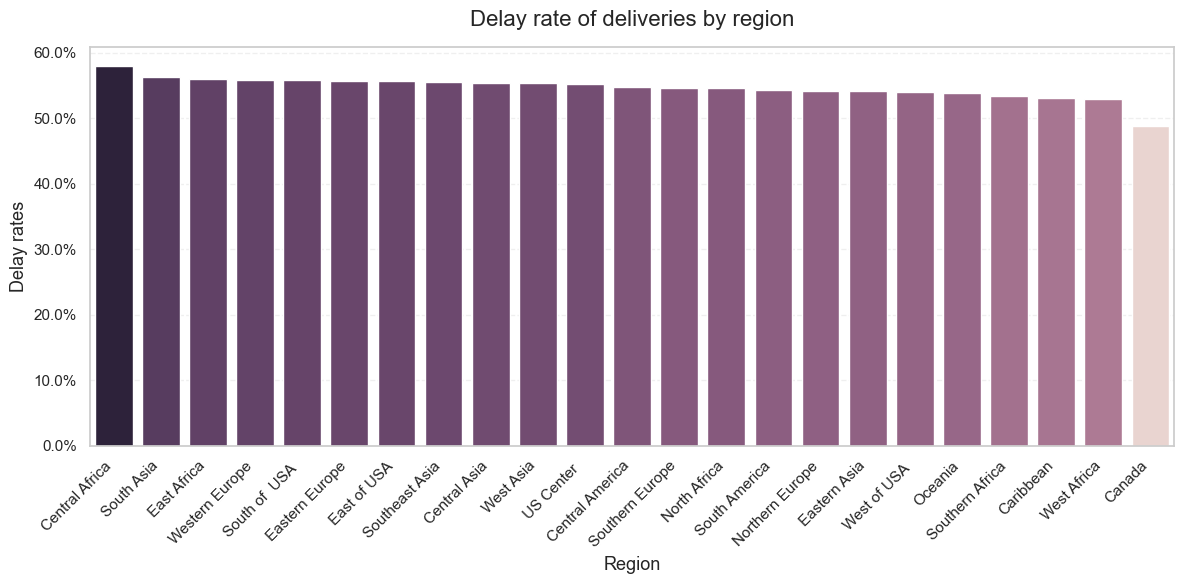

In [30]:
total_by_region = data['order_region'].value_counts()

late_by_region = data[data['delivery_status'] == 'Late delivery']['order_region'].value_counts()

late_rate = (late_by_region / total_by_region).fillna(0).sort_values(ascending=False)
late_df = late_rate.reset_index()
late_df.columns = ['order_region', 'late_rate']

plt.figure(figsize=(12, 6))
sns.barplot(
    data=late_df,
    x='order_region',
    y='late_rate',
    hue='late_rate',
    dodge=False
)

plt.title("Delay rate of deliveries by region", fontsize=16, pad=15)
plt.xlabel("Region", fontsize=13)
plt.ylabel("Delay rates", fontsize=13)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=11)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.1%}'))

plt.legend([], [], frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** Late delivery rates differ by region. This introduces an important operational risk pattern that was not the main focus of the original hypotheses but appears strong enough to consider for modelling.


## 2.4 Late Delivery Risk by Shipping Mode and Market


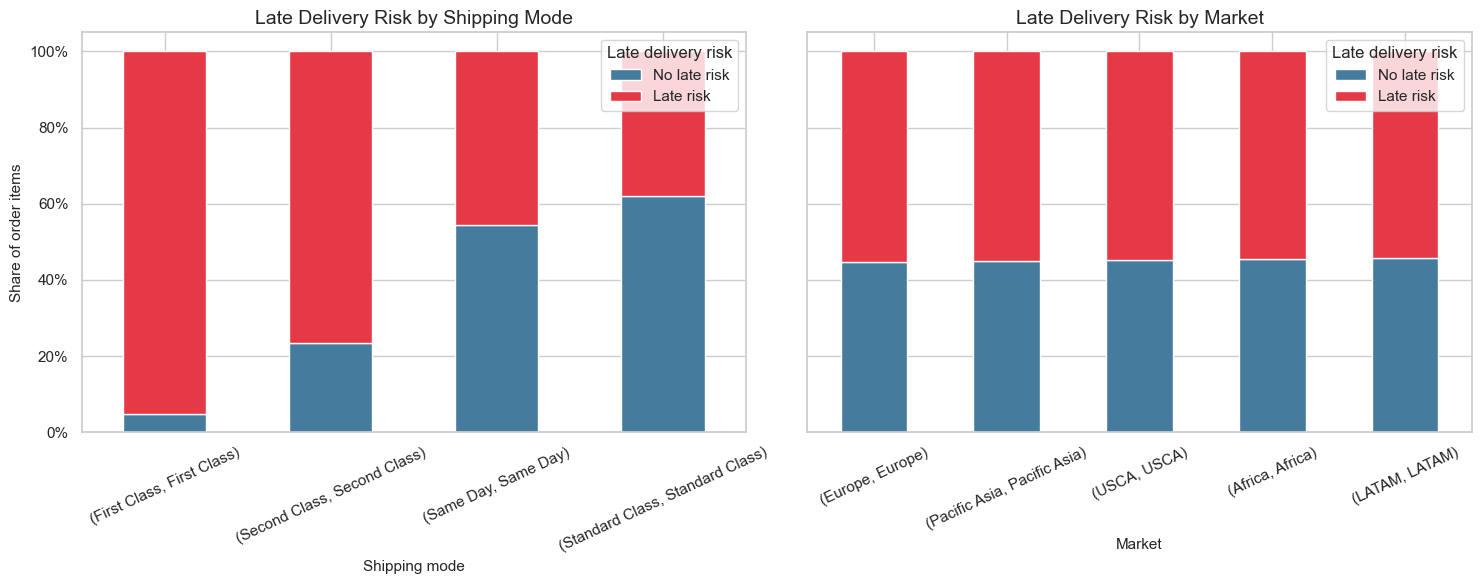

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

mode_late = (
    data.groupby(['shipping_mode', 'late_delivery_risk'])
        .size()
        .groupby(level=0)
        .apply(lambda x: x / x.sum())
        .unstack(fill_value=0)
)
mode_late = mode_late.loc[mode_late.get(1, pd.Series(0, index=mode_late.index)).sort_values(ascending=False).index]
mode_late.plot(kind='bar', stacked=True, color=['#457B9D', '#E63946'], ax=axes[0])
axes[0].set_title('Late Delivery Risk by Shipping Mode')
axes[0].set_xlabel('Shipping mode')
axes[0].set_ylabel('Share of order items')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].legend(['No late risk', 'Late risk'], title='Late delivery risk')
axes[0].tick_params(axis='x', rotation=25)

market_late = (
    data.groupby(['market', 'late_delivery_risk'])
        .size()
        .groupby(level=0)
        .apply(lambda x: x / x.sum())
        .unstack(fill_value=0)
)
market_late = market_late.loc[market_late.get(1, pd.Series(0, index=market_late.index)).sort_values(ascending=False).index]
market_late.plot(kind='bar', stacked=True, color=['#457B9D', '#E63946'], ax=axes[1])
axes[1].set_title('Late Delivery Risk by Market')
axes[1].set_xlabel('Market')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].legend(['No late risk', 'Late risk'], title='Late delivery risk')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()


**Interpretation:** This bivariate analysis shows that late delivery risk changes by both shipping mode and market. The finding adds an operational-risk dimension to the original hypotheses, which focused more on product features and fraud.


## 2.5 Sales vs Benefit Per Order


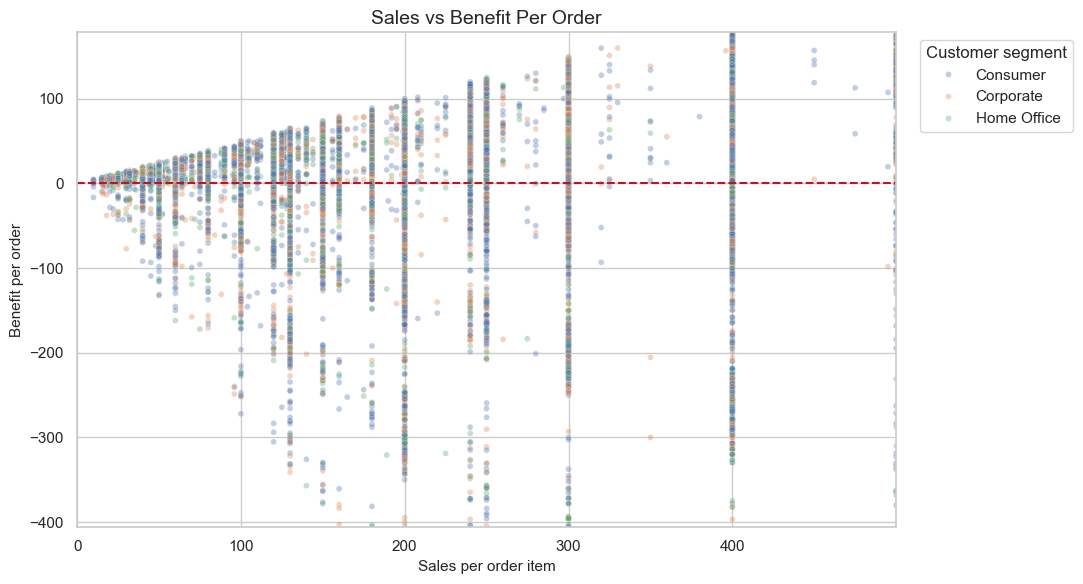

Correlation between sales and benefit per order: 0.119


In [32]:
sales_benefit_sample = data.sample(n=min(25000, len(data)), random_state=42).copy()
sales_limit = data['sales'].quantile(0.99)
benefit_low = data['benefit_per_order'].quantile(0.01)
benefit_high = data['benefit_per_order'].quantile(0.99)
sales_benefit_sample = sales_benefit_sample[
    (sales_benefit_sample['sales'] <= sales_limit) &
    (sales_benefit_sample['benefit_per_order'].between(benefit_low, benefit_high))
]

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(
    data=sales_benefit_sample,
    x='sales',
    y='benefit_per_order',
    hue='customer_segment',
    alpha=0.35,
    s=18,
    ax=ax
)
ax.axhline(0, color='#C1121F', linestyle='--', linewidth=1.5)
ax.set_xlim(0, sales_limit)
ax.set_ylim(benefit_low, benefit_high)
ax.set_title('Sales vs Benefit Per Order')
ax.set_xlabel('Sales per order item')
ax.set_ylabel('Benefit per order')
ax.legend(title='Customer segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

corr_sales_benefit = data[['sales', 'benefit_per_order']].corr().iloc[0, 1]
print(f"Correlation between sales and benefit per order: {corr_sales_benefit:.3f}")


**Interpretation:** Sales and benefit are related, but high sales do not guarantee positive profit. This means the team should be careful about defining success only as higher sales; profitability and loss risk are separate business concerns.


## 2.6 Loss Rate by Region


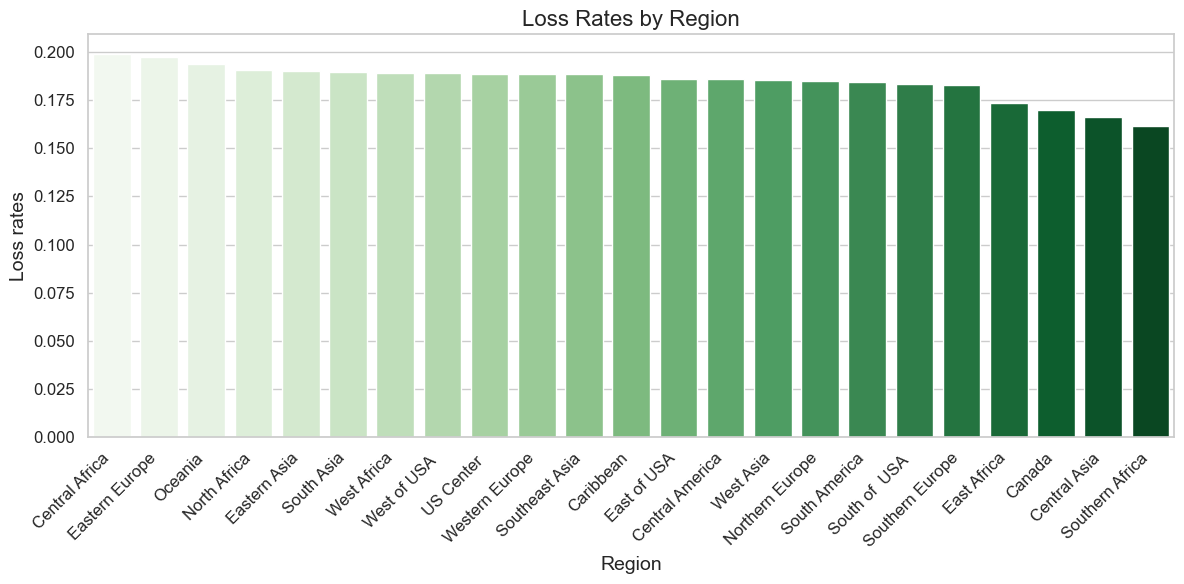

Total number of lost orders：32179
Total order loss amount：-3,617,894.11 $
Loss rate of each region：
order_region
Central Africa     19.92%
Eastern Europe     19.72%
Oceania            19.38%
North Africa       19.09%
Eastern Asia       19.00%
South Asia         18.98%
West Africa        18.91%
West of USA        18.90%
US Center          18.87%
Western Europe     18.86%
Southeast Asia     18.86%
Caribbean          18.83%
East of USA        18.60%
Central America    18.59%
West Asia          18.54%
Northern Europe    18.47%
South America      18.44%
South of  USA      18.32%
Southern Europe    18.27%
East Africa        17.33%
Canada             17.00%
Central Asia       16.64%
Southern Africa    16.16%
Name: count, dtype: object


In [33]:
loss_counts = loss['order_region'].value_counts()      
total_counts = data['order_region'].value_counts()   

loss_rate = (loss_counts / total_counts).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=loss_rate.index,
    y=loss_rate.values,
    hue=loss_rate.index,
    palette='Greens',
    legend=False
)

plt.title('Loss Rates by Region', fontsize=16)
plt.xlabel('Region', fontsize=14)
plt.ylabel('Loss rates', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

print(f"Total number of lost orders：{len(loss)}")
print(f"Total order loss amount：{loss['benefit_per_order'].sum():,.2f} $")
print("Loss rate of each region：")
print(loss_rate.apply(lambda x: f"{x:.2%}"))


**Interpretation:** Loss rates differ across regions, which suggests that regional business conditions, product mix, discounting, or logistics may influence profitability. This is a risk pattern worth checking before modelling.


# 3. Multivariate Analysis

Multivariate analysis considers three or more variables or examines how one relationship changes across grouped conditions. These charts connect product, time, market, shipping mode, delivery risk, sales, and profitability.


## 3.1 Average Monthly Quantity for Top Products


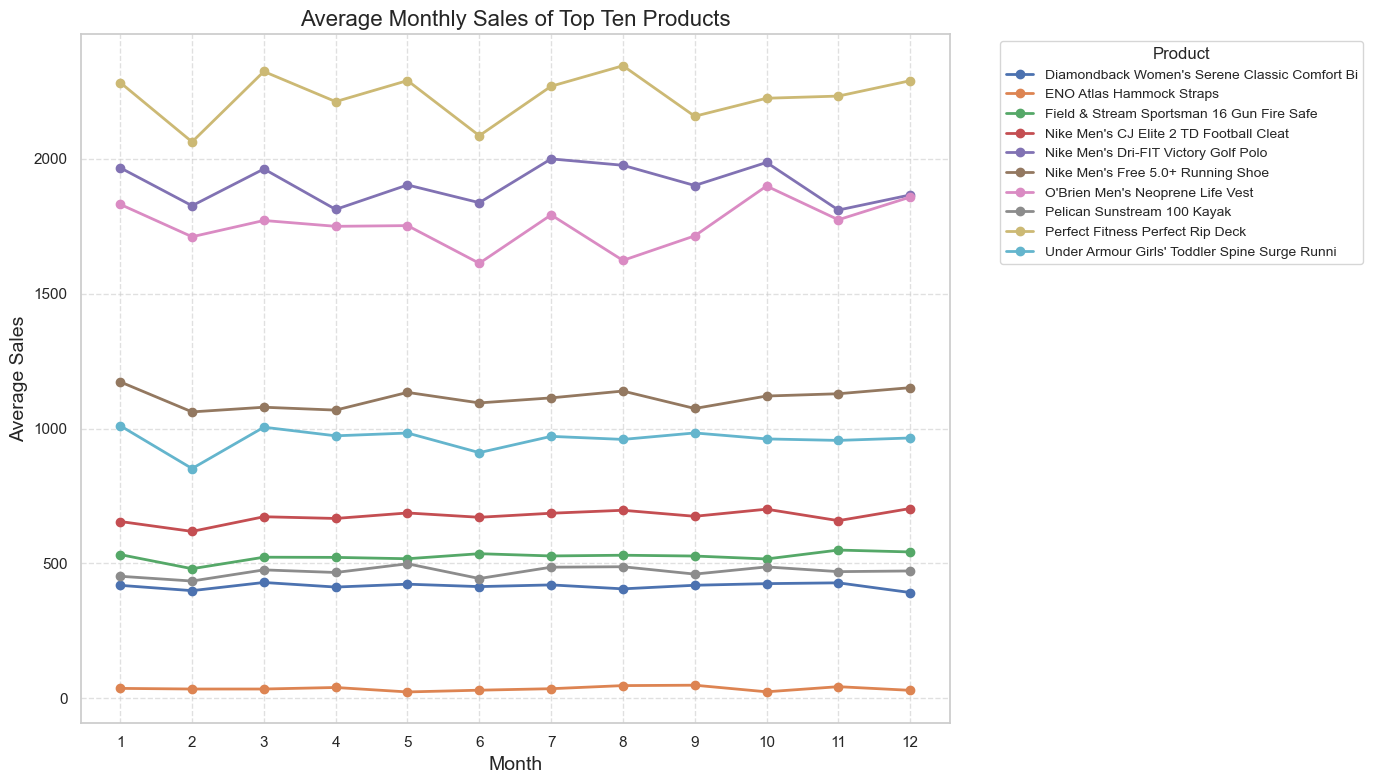

In [34]:
# Identify the top ten best-selling products (based on three-year average sales)
top_products = data.groupby('product_name')['order_item_quantity'].sum().nlargest(10).index

# Group by product, year, and month to calculate the monthly sales revenue for each product each year
yearly_monthly_sales = data[data['product_name'].isin(top_products)].groupby(
    ['product_name', 'ORDER_YEAR', 'ORDER_MONTH']
)['order_item_quantity'].sum().reset_index()

# Calculate the three-year average sales revenue of each product in each month
monthly_avg_sales = yearly_monthly_sales.groupby(['product_name', 'ORDER_MONTH'])['order_item_quantity'].mean().reset_index()

# Convert to pivot table for drawing purposes
monthly_avg_pivot = monthly_avg_sales.pivot(index='product_name', columns='ORDER_MONTH', values='order_item_quantity').fillna(0)

# Draw a line chart
plt.figure(figsize=(14, 8))
for product in monthly_avg_pivot.index:
    plt.plot(monthly_avg_pivot.columns, monthly_avg_pivot.loc[product], marker='o', label=product, linewidth=2)

# Set title and axis labels
plt.title("Average Monthly Sales of Top Ten Products", fontsize=16)
plt.xlabel("Month", fontsize=14)
plt.ylabel("Average Sales", fontsize=14)
plt.xticks(range(1, 13), [str(i) for i in range(1, 13)])  
plt.legend(title="Product", fontsize=10, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


**Interpretation:** The top products have different monthly quantity patterns, so product performance is not uniform over time. This strengthens the idea that both product features and time features should be considered together.


## 3.2 Late Delivery Rate by Region and Shipping Mode


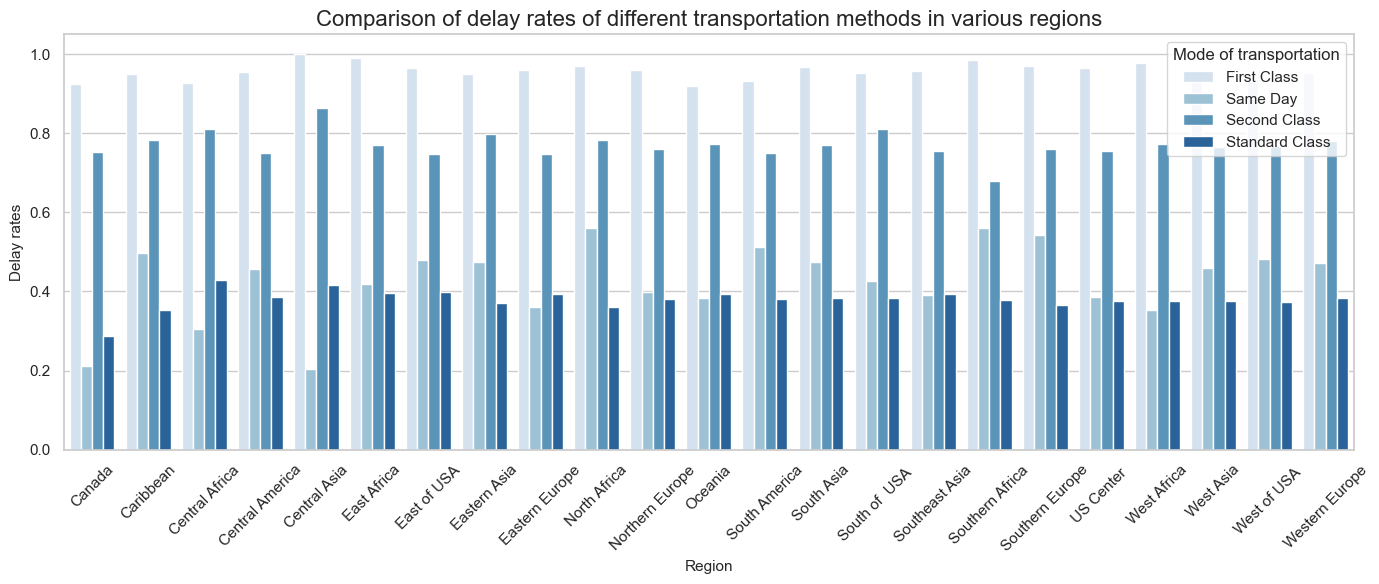

In [35]:
delay_rate = (
    data.groupby(['order_region', 'shipping_mode'])['late_delivery_risk']
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=delay_rate,
    x='order_region',
    y='late_delivery_risk',
    hue='shipping_mode',
    palette='Blues'
)

plt.title('Comparison of delay rates of different transportation methods in various regions', fontsize=16)
plt.xlabel('Region')
plt.ylabel('Delay rates')
plt.legend(title='Mode of transportation', loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Interpretation:** Late delivery risk changes across both region and shipping mode. This is already a multivariate pattern because the relationship between delivery risk and shipping mode depends on region.


## 3.3 Shipping Mode Mix by Market


<Figure size 1200x600 with 0 Axes>

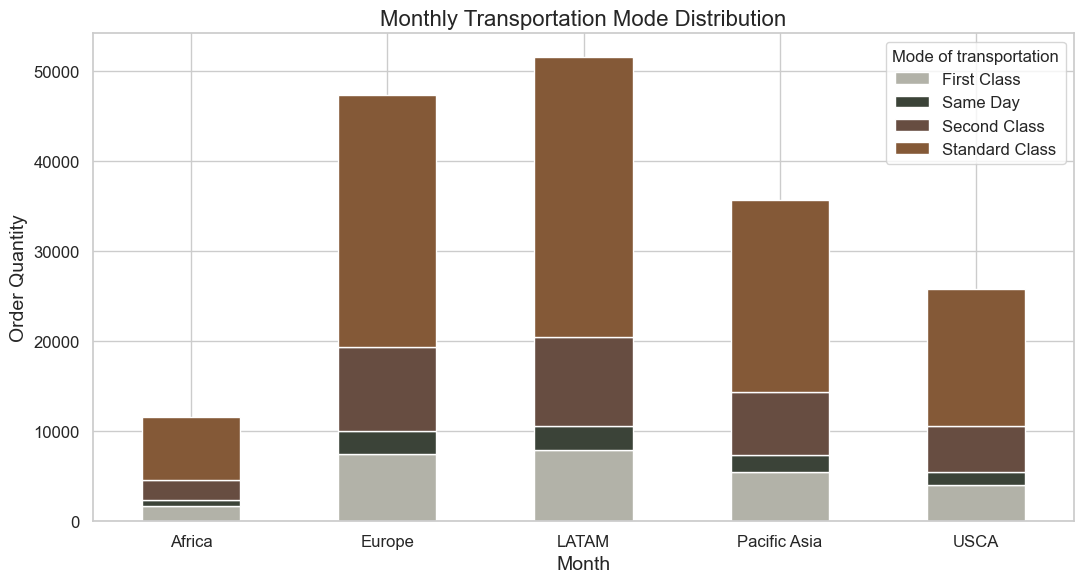

In [36]:
data['shipping_date_dateorders'] = pd.to_datetime(data['shipping_date_dateorders'])


data['Year'] = data['shipping_date_dateorders'].dt.year
data['Month'] = data['shipping_date_dateorders'].dt.month


# Group by month and transportation method, calculate the quantity of each transportation method
monthly_shipping = data.groupby(['market', 'shipping_mode']).size().unstack(fill_value=0)

# Define the colors of the Morandi color palette
morandi_colors = ['#B2B2A8', '#3B4338', '#674D41', '#845937', '#B89886', '#927157', '#59321D', '#8F6849', '#C5BDB2', '#A39183']


plt.figure(figsize=(12, 6))
ax = monthly_shipping.plot(kind='bar', stacked=True, color=morandi_colors, rot=0)
plt.title("Monthly Transportation Mode Distribution", fontsize=16)
plt.xlabel("Month", fontsize=14)
plt.ylabel("Order Quantity", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title="Mode of transportation", fontsize=12)

plt.tight_layout()
plt.show()

**Interpretation:** Although the original title says monthly distribution, the code groups orders by market and shipping mode. The chart still shows useful information: markets rely on different mixes of shipping modes, which may partly explain market-level delivery risk.


## 3.4 Late Delivery Rate by Market and Shipping Mode


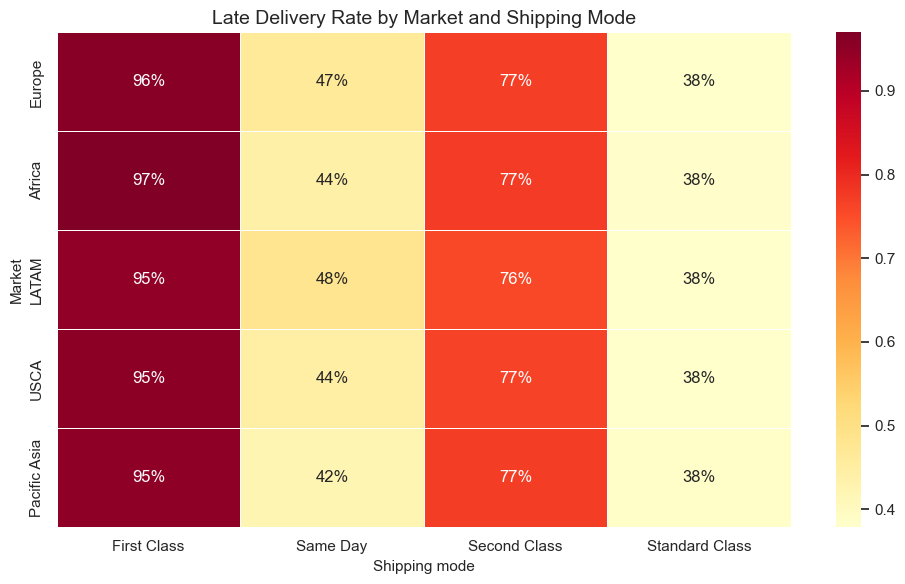

In [37]:
late_market_mode = (
    data.groupby(['market', 'shipping_mode'])['late_delivery_risk']
        .mean()
        .reset_index()
)
late_market_mode_pivot = late_market_mode.pivot(index='market', columns='shipping_mode', values='late_delivery_risk')
late_market_mode_pivot = late_market_mode_pivot.loc[late_market_mode_pivot.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(late_market_mode_pivot, annot=True, fmt='.0%', cmap='YlOrRd', linewidths=0.5, ax=ax)
ax.set_title('Late Delivery Rate by Market and Shipping Mode')
ax.set_xlabel('Shipping mode')
ax.set_ylabel('Market')
plt.tight_layout()
plt.show()


**Interpretation:** This multivariate heatmap compares late delivery risk across market and shipping mode at the same time. The risk level depends on the combination of geography and shipping choice, so later models should allow interactions between these features.


## 3.5 Product Category Sales, Profit, and Late Delivery Risk


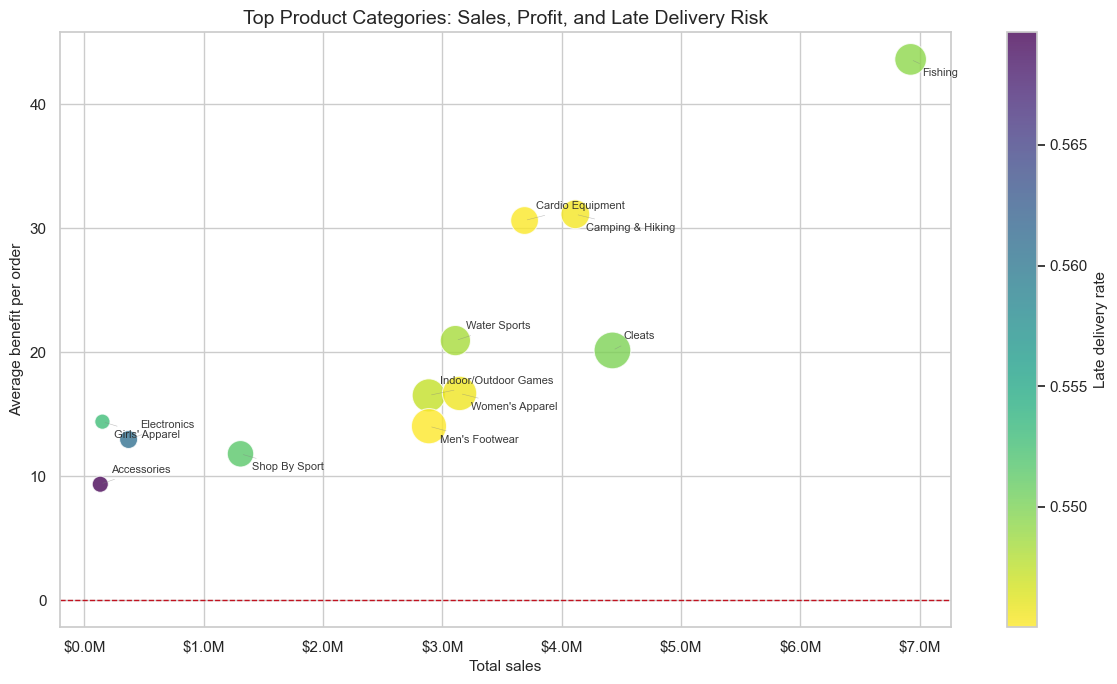

In [38]:
category_summary = (
    data.groupby('category_name', as_index=False)
        .agg(total_sales=('sales', 'sum'), avg_benefit=('benefit_per_order', 'mean'), late_rate=('late_delivery_risk', 'mean'), order_items=('order_id', 'count'))
)
category_summary = category_summary[category_summary['order_items'] >= 100].copy()
top_category_summary = category_summary.sort_values('total_sales', ascending=False).head(12)
top_category_summary = top_category_summary.sort_values('total_sales', ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))
scatter = ax.scatter(
    top_category_summary['total_sales'],
    top_category_summary['avg_benefit'],
    s=np.interp(top_category_summary['order_items'],
                (top_category_summary['order_items'].min(), top_category_summary['order_items'].max()),
                (120, 700)),
    c=top_category_summary['late_rate'],
    cmap='viridis_r',
    alpha=0.78,
    edgecolor='white',
    linewidth=0.8
)
for i, (_, row) in enumerate(top_category_summary.iterrows()):
    offset = 8 if i % 2 == 0 else -12
    ax.annotate(
        row['category_name'],
        xy=(row['total_sales'], row['avg_benefit']),
        xytext=(8, offset),
        textcoords='offset points',
        fontsize=8,
        alpha=0.9,
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.4, alpha=0.5)
    )
ax.axhline(0, color='#C1121F', linestyle='--', linewidth=1)
ax.set_title('Top Product Categories: Sales, Profit, and Late Delivery Risk')
ax.set_xlabel('Total sales')
ax.set_ylabel('Average benefit per order')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Late delivery rate')
plt.tight_layout()
plt.show()


**Interpretation:** This multivariate product-category chart avoids the label overlap problem by using offset annotations. It shows that product categories differ across sales, average profit, order volume, and late delivery risk, so product features should be combined with operational variables in later modelling.


# Revised Hypotheses Based on EDA

Based on the univariate, bivariate, and multivariate EDA, the team's original hypotheses should be revised as follows:

1. **Original: Product features have a significant impact on sales. Revised: strongly supported.** The EDA shows clear differences in product quantity, product category performance, and monthly patterns among top products. This supports keeping product-related variables such as `category_id`, `product_name`, and `order_item_quantity` in the later sales prediction model.

2. **Original: Sales may exhibit seasonal distribution. Revised: partially supported.** Monthly sales vary across months and years, and order volume also changes by hour of day. This does not prove formal seasonality, but it supports using time variables such as `ORDER_MONTH`, `ORDER_YEAR`, weekday, or hour as candidate predictors of sales.

3. **Original: Fraud may be related to payment methods and geographic regions. Revised: partially supported, but better suited as contextual analysis than the main modelling target.** The EDA shows suspected fraud patterns by payment type, product category, customer, and region. However, the team's existing modelling work is already structured as a sales regression task, so fraud should be discussed as a business risk rather than replacing the modelling target.

4. **Original: Western Europe and Central America are high-fraud areas. Revised: needs rate-based verification.** Fraud counts alone can be misleading because regions have different order volumes. The report should frame this as a hypothesis that requires regional fraud-rate comparison rather than a confirmed conclusion from count charts alone.

5. **Original: Fraud rate may be related to economic level and payment methods. Revised: only payment method can be examined directly in this dataset.** The dataset contains payment and geography fields, but it does not contain external economic-level indicators. Any claim about regional economic level would need outside data.

6. **EDA-driven modelling direction: continue with sales prediction, but use EDA to justify the feature set.** The EDA indicates that sales differ by product, market, region, order quantity, and time. Therefore, the most consistent next step is to continue the existing supervised regression approach and refine it using the EDA findings.


# Clear Modelling Question

**Machine learning objective:** Build a supervised regression model that predicts order-item sales using product, customer, geography, quantity, and time-related features identified during EDA.

**Formal modelling question:** Given an order item's product category or product name, customer location, market, order city/country, order region, order quantity, order month, and order year, can we predict the continuous target variable `sales`?

This is a **regression** problem, which aligns with the team's previous modelling work using Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor. The main evaluation metrics should remain regression metrics such as MSE, RMSE, MAE, and R-squared.

**Target variable:** `sales`.

**Candidate feature groups:**
- Product features: `category_id`, `product_name`, product category/department fields if included.
- Geography features: `customer_city`, `customer_country`, `market`, `order_city`, `order_country`, `order_region`.
- Order features: `order_item_quantity`, product price or discount variables if added later.
- Time features: `ORDER_MONTH`, `ORDER_YEAR`, and optionally weekday or hour.
- Customer segmentation features: RFM segment can be considered as an additional engineered feature if it is built without data leakage.

**Connection to the existing model:** The previous model already uses `category_id`, `customer_city`, `customer_country`, `market`, `order_city`, `order_country`, `order_item_quantity`, `order_region`, `product_name`, `ORDER_MONTH`, and `ORDER_YEAR` to predict `sales`. The EDA supports this direction because these variables show meaningful variation in sales patterns.

**Leakage caution:** Avoid using variables that are direct transformations of the target or are only known after the sale outcome in a way that would not be available at prediction time. For example, if predicting sales before order completion, features such as final order totals or profit-derived variables should be handled carefully.


# EDA Summary for the Written Report

The EDA shows that sales are unevenly distributed across products, markets, regions, and time periods. Product-level charts support the team's original expectation that product features matter for sales, while monthly and hourly patterns suggest that time features may also improve prediction. Market and regional sales charts show geographic variation, and the RFM analysis provides a possible customer-level extension for future feature engineering.

Fraud and delivery-risk analyses remain useful business context. Suspected fraud appears related to payment type, product category, customer, and region, but the evidence is better used to refine hypotheses than to replace the existing modelling direction. Late delivery risk also varies by market, region, and shipping mode, which may become a future classification project, but it is not necessary to switch targets for the next modelling milestone.

Therefore, the recommended next modelling step is to continue with the existing **sales prediction regression** framework and improve it using EDA-supported features. This keeps continuity with the team's previous Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor work while making the feature choices more defensible.
